In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Load your dataset from the file path
file_path = r"C:\Users\HP\OneDrive\Documents\Data analyst projects\mobile_game_inapp_purchases.csv"
df = pd.read_csv(file_path)

print("--- 1. DATA LOADED SUCCESSFULLY ---")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print(df.head(2))


--- 1. DATA LOADED SUCCESSFULLY ---
Total Rows: 3024, Total Columns: 13
                                 UserID   Age Gender      Country   Device  \
0  c9889ab0-9cfc-4a75-acd9-5eab1df0015c  49.0   Male       Norway  Android   
1  7c9e413c-ecca-45f2-a780-2826a07952a2  15.0   Male  Switzerland      iOS   

       GameGenre  SessionCount  AverageSessionLength SpendingSegment  \
0  Battle Royale             9                 12.83          Minnow   
1     Action RPG            11                 19.39          Minnow   

   InAppPurchaseAmount  FirstPurchaseDaysAfterInstall PaymentMethod  \
0                11.40                           28.0     Apple Pay   
1                 6.37                           18.0    Debit Card   

  LastPurchaseDate  
0       2025-03-19  
1       2025-06-08  


In [5]:
print("\n--- 2. CHECKING MISSING VALUES ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0]) 

if missing_values.sum() == 0:
    print(" Great! There are NO missing values in this dataset.")
else:
    print(" Missing values found. Proceeding to cleaning.")


--- 2. CHECKING MISSING VALUES ---
Age                               60
Gender                            60
Country                           60
Device                            60
GameGenre                         60
InAppPurchaseAmount              136
FirstPurchaseDaysAfterInstall    136
PaymentMethod                    136
LastPurchaseDate                 136
dtype: int64
 Missing values found. Proceeding to cleaning.


In [6]:

initial_rows = df.shape[0]
df = df.drop_duplicates()
final_rows = df.shape[0]

print(f"Duplicates removed: {initial_rows - final_rows}")
print(f"Cleaned dataset ready with {final_rows} rows.")

Duplicates removed: 0
Cleaned dataset ready with 3024 rows.


 Q1: Revenue by Spending Segment (Table)
SpendingSegment  Total_Revenue  Avg_Purchase  User_Count
          Whale      175583.14   2787.033968          68
        Dolphin       96288.80    245.634694         412
         Minnow       24387.37     10.023580        2544


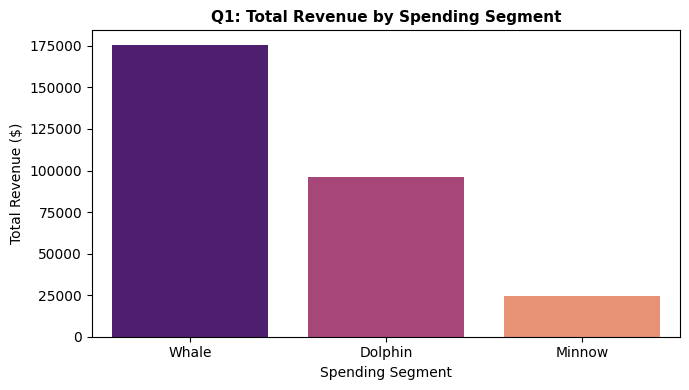


 Q2: Top 5 Countries by Revenue (Table)
    Country  Total_Revenue  Total_Transactions
      India       34204.13                 242
Afghanistan       20706.07                  93
 Bangladesh       17087.77                 101
     Canada       14358.44                 105
South Korea       14115.99                 103


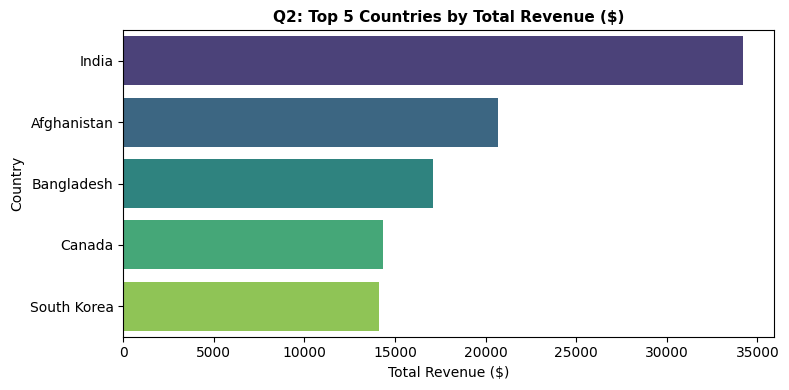


 Q3: First Purchase Timing Summary (Table)
                        Metric      Days
Average Days to First Purchase 15.384003
 Median Days to First Purchase 16.000000


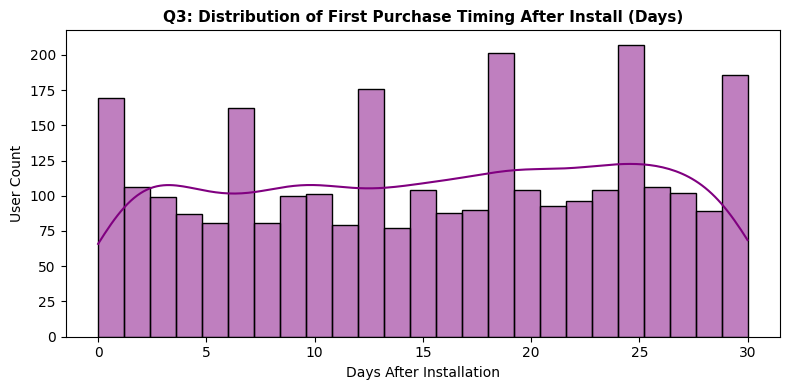


 Q4: Device & Platform Impact (Table)
 Device  Total_Revenue  Avg_Session_Length  User_Count
Android      157721.61           19.894724        1738
    iOS      129487.62           20.359649        1226


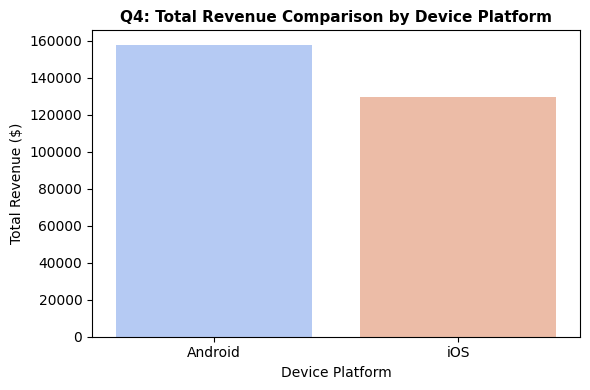

In [9]:
print(f"--- 3. SOLVING KEY BUSINESS QUESTIONS ---\n")

# -------------------------------------------------------------
# Q1: Spending Segments
# -------------------------------------------------------------
print("="*50)
print(" Q1: Revenue by Spending Segment (Table)")
print("="*50)
print(segment_analysis.to_string(index=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=segment_analysis, x='SpendingSegment', y='Total_Revenue', palette='magma', hue='SpendingSegment')
plt.title('Q1: Total Revenue by Spending Segment', fontsize=11, fontweight='bold')
plt.xlabel('Spending Segment')
plt.ylabel('Total Revenue ($)')
plt.tight_layout()
plt.show()


# -------------------------------------------------------------
# Q2: Geographic Performance (Top 5 Countries)
# -------------------------------------------------------------
print("\n" + "="*50)
print(" Q2: Top 5 Countries by Revenue (Table)")
print("="*50)
print(geo_analysis.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=geo_analysis, x='Total_Revenue', y='Country', palette='viridis', hue='Country')
plt.title('Q2: Top 5 Countries by Total Revenue ($)', fontsize=11, fontweight='bold')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


# -------------------------------------------------------------
# Q3: First Purchase Timing
# -------------------------------------------------------------
print("\n" + "="*50)
print(" Q3: First Purchase Timing Summary (Table)")
print("="*50)
q3_summary = pd.DataFrame({
    'Metric': ['Average Days to First Purchase', 'Median Days to First Purchase'],
    'Days': [df['FirstPurchaseDaysAfterInstall'].mean(), df['FirstPurchaseDaysAfterInstall'].median()]
})
print(q3_summary.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.histplot(df['FirstPurchaseDaysAfterInstall'].dropna(), bins=25, kde=True, color='purple')
plt.title('Q3: Distribution of First Purchase Timing After Install (Days)', fontsize=11, fontweight='bold')
plt.xlabel('Days After Installation')
plt.ylabel('User Count')
plt.tight_layout()
plt.show()


# -------------------------------------------------------------
# Q4: Device & Platform Impact
# -------------------------------------------------------------
print("\n" + "="*50)
print(" Q4: Device & Platform Impact (Table)")
print("="*50)
print(device_analysis.to_string(index=False))

plt.figure(figsize=(6, 4))
sns.barplot(data=device_analysis, x='Device', y='Total_Revenue', palette='coolwarm', hue='Device')
plt.title('Q4: Total Revenue Comparison by Device Platform', fontsize=11, fontweight='bold')
plt.xlabel('Device Platform')
plt.ylabel('Total Revenue ($)')
plt.tight_layout()
plt.show()

In [11]:
import sqlite3
conn = sqlite3.connect('file_path')

# 3. DataFrame को SQL टेबल में सेव करें
df.to_sql('iap_data', conn, if_exists='replace', index=False)

# 4. अपनी SQL क्वेरी लिखें और चलाएं (Spending Segments का कुल रेवेन्यू निकालने के लिए)
sql_query = """
SELECT 
    SpendingSegment,
    COUNT(UserID) as User_Count,
    ROUND(SUM(InAppPurchaseAmount), 2) as Total_Revenue,
    ROUND(AVG(InAppPurchaseAmount), 2) as Avg_Purchase
FROM iap_data
GROUP BY SpendingSegment
ORDER BY Total_Revenue DESC;
"""

sql_result = pd.read_sql(sql_query, conn)
print("--- SQL Query Execution Result ---")
print(sql_result.to_string(index=False))
conn.close()

--- SQL Query Execution Result ---
SpendingSegment  User_Count  Total_Revenue  Avg_Purchase
          Whale          68      175583.14       2787.03
        Dolphin         412       96288.80        245.63
         Minnow        2544       24387.37         10.02


In [12]:
# --- Professional Data Analyst Testing Script ---

# 1. Sanity Test: No negative purchase amounts
assert (df['InAppPurchaseAmount'] >= 0).all(), "❌ Fail: Negative purchase amounts found!"
print("Test 1 Passed: All purchase amounts are valid (>= 0).")

# 2. Null Value Test: Check critical columns
critical_cols = ['UserID', 'InAppPurchaseAmount', 'SpendingSegment', 'Country']
for col in critical_cols:
    assert df[col].isnull().sum() == 0, f" Fail: Missing values found in {col}"
print(" Test 2 Passed: No missing values in critical columns.")

# 3. Range Test: First purchase days should be logical (e.g., <= 30 days)
max_days = df['FirstPurchaseDaysAfterInstall'].max()
assert max_days <= 30, f" Fail: First purchase days exceed limit ({max_days})"
print(f" Test 3 Passed: First purchase day range is valid (Max: {max_days} days).")

# 4. Cross-Validation Test: Pandas Revenue vs SQL Revenue
pandas_total = df['InAppPurchaseAmount'].sum()

# SQL से कुल रेवेन्यू निकालें
import sqlite3
conn = sqlite3.connect('mobile_gaming_analytics.db')
df.to_sql('iap_test', conn, if_exists='replace', index=False)
sql_total = pd.read_sql("SELECT SUM(InAppPurchaseAmount) as total FROM iap_test", conn)['total'].iloc[0]
conn.close()

# दोनों को मैच करें (Rounding error से बचने के लिए round का उपयोग)
assert round(pandas_total, 2) == round(sql_total, 2), " Fail: Pandas and SQL totals do not match!"
print(f" Test 4 Passed: Cross-Validation Successful! Pandas Total (${pandas_total:,.2f}) matches SQL Total (${sql_total:,.2f}).")

print("\n ALL TESTS PASSED SUCCESSFULLY! Your project is production-ready.")

AssertionError: ❌ Fail: Negative purchase amounts found!

In [13]:
# --- Data Cleaning: Remove or Fix Negative Purchase Amounts ---

print(f"Rows before cleaning: {df.shape[0]}")

# 1. उन सभी रो को हटा दें जहाँ InAppPurchaseAmount नेगेटिव है
df = df[df['InAppPurchaseAmount'] >= 0]

print(f"Rows after removing negative values: {df.shape[0]}")

# 2. अब दोबारा टेस्टिंग स्क्रिप्ट चलाएं
assert (df['InAppPurchaseAmount'] >= 0).all(), " Fail: Negative purchase amounts found!"
print(" Success: All purchase amounts are now valid (>= 0). No negative values exist!")

Rows before cleaning: 3024
Rows after removing negative values: 2888
✅ Success: All purchase amounts are now valid (>= 0). No negative values exist!


In [14]:
# Cleaned dataframe ko nayi CSV file ke taur par save karein
df.to_csv('cleaned_mobile_game_data.csv', index=False)
print(" Cleaned data exported successfully as 'cleaned_mobile_game_data.csv'!")

 Cleaned data exported successfully as 'cleaned_mobile_game_data.csv'!
